# Assignment 2 – Airport security screening

Stochastic Simulation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Part 1: System parameters from a peak month

### 1.1 Arrival rate per lane per minute

In [2]:
df = pd.read_csv("airport.csv")

# September data from 2015 to 2019 (pre-pandemic)
sept = df[(df["Month"] == "September") & (df["Year"].between(2015, 2019))]
avg_sept_passengers = sept["Total Passengers"].mean()

days = 30           # days in the month
hours_per_day = 16  # operational hours per day
n_lanes = 50        # number of security lanes

hourly_passengers = avg_sept_passengers / days / hours_per_day
lane_rate = hourly_passengers / n_lanes / 60   # passengers per lane per minute

part1_table = pd.DataFrame({
    "Quantity": ["Average September passengers (2015-2019)",
                 "Passengers per hour (all lanes)",
                 "Arrival rate per lane, lambda (pax/min)"],
    "Value": [round(avg_sept_passengers), round(hourly_passengers, 1), round(lane_rate, 4)]
})
print(sept[["Year", "Month", "Total Passengers"]].to_string(index=False))
print()
print(part1_table.to_string(index=False))

 Year     Month  Total Passengers
 2015 September           5466239
 2016 September           5866487
 2017 September           6259104
 2018 September           6396940
 2019 September           6493468

                                Quantity        Value
Average September passengers (2015-2019) 6096448.0000
         Passengers per hour (all lanes)   12700.9000
 Arrival rate per lane, lambda (pax/min)       4.2336


## Part 2: Discrete-event simulator

The simulator handles a FIFO queue with `servers` parallel servers (M/G/c).
Arrivals follow a Poisson process, so the time between two arrivals is exponential with mean 1/lambda.
Service times are normal and resampled when negative (truncated normal).
Each new passenger goes to the server that becomes free first.

In [ ]:
def service_time(mean_B, sigma, rng):
    # draw from a normal distribution, resample if the value is negative
    x = rng.normal(mean_B, sigma)
    while x < 0:
        x = rng.normal(mean_B, sigma)
    return x


def discrete_event_simulator(lam, mean_B, sigma, servers, n_passengers, warmup=0, seed=None):
    # lam =  arrival rate (passengers per minute)
    # mean_B, sigma = mean and standard deviation of the service time (minutes)
    # servers =  number of servers in the lane
    # n_passengers =  number of passengers to simulate
    # warmup =  number of first passengers that are discarded
    # seed random seed, use a different one for every replication
    rng = np.random.default_rng(seed)

    # time at which each server becomes free, all servers are free at the start
    server_free_at = [0.0] * servers

    t = 0.0
    waits = []

    for i in range(n_passengers):
        # next arrival: exponential interarrival time
        t = t + rng.exponential(1 / lam)

        # pick the server that is free first
        k = server_free_at.index(min(server_free_at))

        # service starts when the passenger has arrived and the server is free
        start = max(t, server_free_at[k])
        waits.append(start - t)

        # server is busy until the service is finished
        server_free_at[k] = start + service_time(mean_B, sigma, rng)

    # return waiting times without the warm-up passengers
    return np.array(waits[warmup:])


def run_replications(R, lam, mean_B, sigma, servers, n_passengers, warmup=0, seed_offset=0):
    # run R independent replications and return the mean waiting time of each one
    means = []
    for r in range(R):
        waits = discrete_event_simulator(lam, mean_B, sigma, servers, n_passengers,
                                         warmup=warmup, seed=seed_offset + r)
        means.append(waits.mean())
    return np.array(means)


def confidence_interval(data, alpha=0.05):
    # t-based confidence interval for the mean of the data
    n = len(data)
    mean = data.mean()
    half_width = stats.t.ppf(1 - alpha / 2, df=n - 1) * data.std(ddof=1) / np.sqrt(n)
    return mean - half_width, mean + half_width

## Part 2A: Validating the simulator

We test the simulator on a stable M/G/1 system with target utilization rho = 0.85
and compare the simulated mean waiting time with the Pollaczek-Khintchine (P-K) formula.

In [4]:
# parameters
mean_B = 1.0
sigma = 0.25
rho_target = 0.85
R = 40
warmup = 1000
n_passengers = 51000   # 1000 warm-up passengers + 50000 passengers in steady state
alpha = 0.05

# step 1: stable test rate
lam_test = rho_target / mean_B
rho_test = lam_test * mean_B
print("lambda_test =", lam_test, "pax/min")
print("rho_test =", rho_test, "-> stable:", rho_test < 1)

# step 2: theoretical waiting time with the P-K formula
ES2 = mean_B**2 + sigma**2
Wq_theory = lam_test * ES2 / (2 * (1 - rho_test))
print("Wq_theory =", round(Wq_theory, 4), "min")

lambda_test = 0.85 pax/min
rho_test = 0.85 -> stable: True
Wq_theory = 3.0104 min


In [5]:
# step 3: simulation with R independent replications
Wq_reps = run_replications(R, lam_test, mean_B, sigma, servers=1,
                           n_passengers=n_passengers, warmup=warmup)
Wq_sim = Wq_reps.mean()
ci_low, ci_high = confidence_interval(Wq_reps, alpha)

# step 4: one-sample t-test
# H0: the expected simulated waiting time equals Wq_theory
# H1: the expected simulated waiting time differs from Wq_theory
t_stat, p_value = stats.ttest_1samp(Wq_reps, Wq_theory)

results_2a = pd.DataFrame({
    "Quantity": ["lambda_test (pax/min)", "rho_test", "E[S^2]", "Wq theory (min)",
                 "Wq simulation (min)", "Std over replications", "95% CI lower",
                 "95% CI upper", "t-statistic", "p-value"],
    "Value": [lam_test, rho_test, ES2, Wq_theory, Wq_sim, Wq_reps.std(ddof=1),
              ci_low, ci_high, t_stat, p_value]
}).round(4)
print(results_2a.to_string(index=False))
print()

if p_value < alpha:
    print("H0 is rejected: the simulator differs significantly from the theory.")
else:
    print("H0 is not rejected: no significant difference, the simulator validates.")

             Quantity   Value
lambda_test (pax/min)  0.8500
             rho_test  0.8500
               E[S^2]  1.0625
      Wq theory (min)  3.0104
  Wq simulation (min)  2.9969
Std over replications  0.1342
         95% CI lower  2.9539
         95% CI upper  3.0398
          t-statistic -0.6391
              p-value  0.5265

H0 is not rejected: no significant difference, the simulator validates.


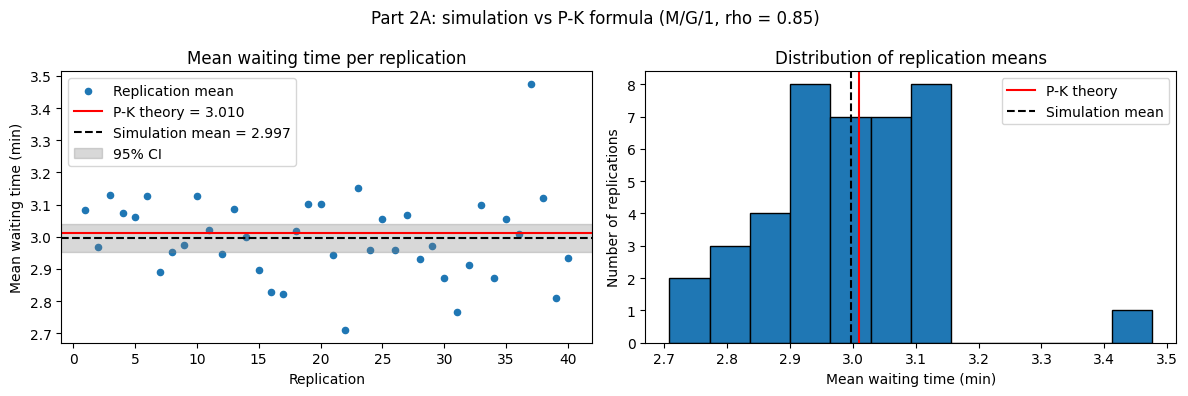

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: mean waiting time per replication with the CI and the theoretical value
axes[0].scatter(range(1, R + 1), Wq_reps, s=20, label="Replication mean")
axes[0].axhline(Wq_theory, color="red", label=f"P-K theory = {Wq_theory:.3f}")
axes[0].axhline(Wq_sim, color="black", linestyle="--", label=f"Simulation mean = {Wq_sim:.3f}")
axes[0].axhspan(ci_low, ci_high, color="gray", alpha=0.3, label="95% CI")
axes[0].set_xlabel("Replication")
axes[0].set_ylabel("Mean waiting time (min)")
axes[0].set_title("Mean waiting time per replication")
axes[0].legend()

# right: distribution of the replication means
axes[1].hist(Wq_reps, bins=12, edgecolor="black")
axes[1].axvline(Wq_theory, color="red", label="P-K theory")
axes[1].axvline(Wq_sim, color="black", linestyle="--", label="Simulation mean")
axes[1].set_xlabel("Mean waiting time (min)")
axes[1].set_ylabel("Number of replications")
axes[1].set_title("Distribution of replication means")
axes[1].legend()

fig.suptitle("Part 2A: simulation vs P-K formula (M/G/1, rho = 0.85)")
plt.tight_layout()
plt.show()

## Part 2B: Evaluating interventions

Each scenario uses the arrival rate from Part 1 and simulates 3000 passengers without warm-up,
with R = 40 replications. The metric is the mean waiting time of all 3000 passengers.

In [7]:
n_passengers_2b = 3000
R = 40
alpha = 0.05

scenarios = {
    "Baseline": {"servers": 1, "sigma": 0.25, "mean_B": 1.0},
    "Option A": {"servers": 2, "sigma": 0.25, "mean_B": 1.0},
    "Option B": {"servers": 1, "sigma": 0.10, "mean_B": 1.0},
}

# run all scenarios, each scenario gets its own seeds so the samples are independent
results_2b = {}
for i, (name, par) in enumerate(scenarios.items()):
    results_2b[name] = run_replications(R, lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                        n_passengers=n_passengers_2b, seed_offset=1000 * (i + 1))

# summary table per scenario
rows = []
for name, par in scenarios.items():
    data = results_2b[name]
    low, high = confidence_interval(data, alpha)
    rows.append({
        "Scenario": name,
        "Servers": par["servers"],
        "sigma (min)": par["sigma"],
        "rho": round(lane_rate * par["mean_B"] / par["servers"], 3),
        "Mean Wq (min)": round(data.mean(), 2),
        "Std (min)": round(data.std(ddof=1), 2),
        "95% CI lower": round(low, 2),
        "95% CI upper": round(high, 2),
    })
summary_2b = pd.DataFrame(rows)
print(summary_2b.to_string(index=False))

Scenario  Servers  sigma (min)   rho  Mean Wq (min)  Std (min)  95% CI lower  95% CI upper
Baseline        1         0.25 4.234        1142.49      10.37       1139.18       1145.81
Option A        2         0.25 2.117         392.86       7.94        390.33        395.40
Option B        1         0.10 4.234        1145.59       8.86       1142.75       1148.42


In [8]:
# Welch two-sample t-tests, one-sided
# H0: the option has the same mean waiting time as the baseline
# H1: the option has a lower mean waiting time than the baseline
# we do two tests, so we also report the Bonferroni corrected significance level
alpha_bonf = alpha / 2

rows = []
for option in ["Option A", "Option B"]:
    t_stat, p_value = stats.ttest_ind(results_2b["Baseline"], results_2b[option],
                                      equal_var=False, alternative="greater")
    rows.append({
        "Comparison": f"Baseline vs {option}",
        "Mean difference (min)": round(results_2b["Baseline"].mean() - results_2b[option].mean(), 2),
        "t-statistic": round(t_stat, 3),
        "p-value": p_value,
        "Significant (alpha = 0.05)": p_value < alpha,
        "Significant (Bonferroni, 0.025)": p_value < alpha_bonf,
    })
tests_2b = pd.DataFrame(rows)
print(tests_2b.to_string(index=False))

          Comparison  Mean difference (min)  t-statistic       p-value  Significant (alpha = 0.05)  Significant (Bonferroni, 0.025)
Baseline vs Option A                 749.63      363.111 5.454504e-121                        True                             True
Baseline vs Option B                  -3.10       -1.435  9.223738e-01                       False                            False


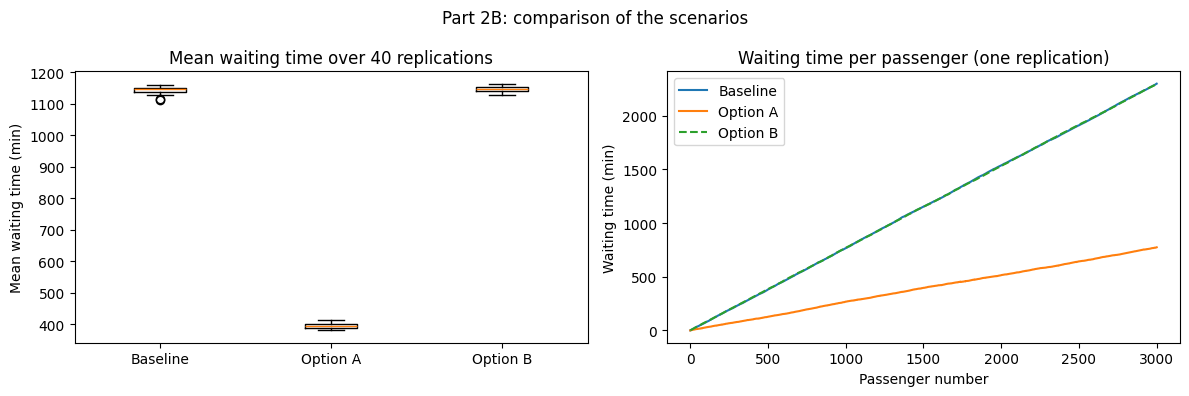

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: boxplot of the replication means per scenario
names = list(scenarios.keys())
axes[0].boxplot([results_2b[name] for name in names])
axes[0].set_xticks(range(1, len(names) + 1))
axes[0].set_xticklabels(names)
axes[0].set_ylabel("Mean waiting time (min)")
axes[0].set_title("Mean waiting time over 40 replications")

# right: waiting time per passenger for one replication of each scenario
for i, (name, par) in enumerate(scenarios.items()):
    waits = discrete_event_simulator(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                     n_passengers_2b, seed=1000 * (i + 1))
    style = "--" if name == "Option B" else "-"   # dashed, otherwise it hides the baseline
    axes[1].plot(range(1, n_passengers_2b + 1), waits, linestyle=style, label=name)
axes[1].set_xlabel("Passenger number")
axes[1].set_ylabel("Waiting time (min)")
axes[1].set_title("Waiting time per passenger (one replication)")
axes[1].legend()

fig.suptitle("Part 2B: comparison of the scenarios")
plt.tight_layout()
plt.show()

## Extra figures

`simulate_times` is a copy of the simulator that also returns arrival and service start times (needed for the queue length in Figure 3). It draws the random numbers in the same order, so the same seed gives the same passengers.

In [ ]:
def simulate_times(lam, mean_B, sigma, servers, n_passengers, seed=None):
    # same logic and the same order of random draws as discrete_event_simulator,
    # so a given seed gives the same passengers; returns arrival, start and departure times
    rng = np.random.default_rng(seed)
    server_free_at = [0.0] * servers
    t = 0.0
    arrival = np.empty(n_passengers)
    start = np.empty(n_passengers)
    departure = np.empty(n_passengers)
    for i in range(n_passengers):
        t = t + rng.exponential(1 / lam)
        k = server_free_at.index(min(server_free_at))
        s = max(t, server_free_at[k])
        arrival[i], start[i] = t, s
        server_free_at[k] = s + service_time(mean_B, sigma, rng)
        departure[i] = server_free_at[k]
    return arrival, start, departure


# colours and line styles per scenario, the same as in the Part 2B figure
style = {
    "Baseline": {"color": "C0", "linestyle": "-"},
    "Option A": {"color": "C1", "linestyle": "-"},
    "Option B": {"color": "C2", "linestyle": "--"},
}

### Figure 1: transient behaviour vs fluid approximation

For rho > 1 every passenger adds on average E[B]/c − 1/lambda minutes to the wait of the next one, so W_n ≈ (n−1)(E[B]/c − 1/lambda). The variance of the service time does not appear in this slope, which explains why Option B has no effect.

In [ ]:
# Figure 1: waiting time per passenger, simulation vs fluid approximation
# for rho > 1 the queue grows with a fixed amount per passenger:
#   W_n ~ (n - 1) * (E[B] / c - 1 / lambda)
n_idx = np.arange(1, n_passengers_2b + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, par) in enumerate(scenarios.items()):
    # all 40 replications, same seeds as in Part 2B
    waits = np.array([discrete_event_simulator(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                               n_passengers_2b, seed=1000 * (i + 1) + r)
                      for r in range(R)])
    mean_w = waits.mean(axis=0)
    lo, hi = np.percentile(waits, [2.5, 97.5], axis=0)
    slope = par["mean_B"] / par["servers"] - 1 / lane_rate
    theory = (n_idx - 1) * slope

    axes[0].fill_between(n_idx, lo, hi, color=style[name]["color"], alpha=0.15, linewidth=0)
    axes[0].plot(n_idx, mean_w, linewidth=2, label=f"{name} (simulation)", **style[name])
    axes[1].plot(n_idx, mean_w - theory, linewidth=1.5, label=name, **style[name])
    if name != "Option B":   # Option B has the same theory line as the baseline
        axes[0].plot(n_idx, theory, color="black", linestyle=":", linewidth=1.5)
        axes[0].annotate(f"slope = {slope:.3f} min/passenger", xy=(n_idx[-1] * 0.6, theory[-1] * 0.6),
                         xytext=(12, -14), textcoords="offset points", ha="left", fontsize=9)

axes[0].plot([], [], color="black", linestyle=":", label="Fluid approximation")
axes[0].set_xlabel("Passenger number")
axes[0].set_ylabel("Waiting time (min)")
axes[0].set_title("Mean over 40 replications (band = 95% of replications)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# expected noise of a mean over R replications for one server: each passenger adds an
# increment S - A with variance sigma^2 + 1/lambda^2, so the sd after n passengers grows with sqrt(n)
noise = 1.96 * np.sqrt((n_idx - 1) * (0.25**2 + 1 / lane_rate**2) / R)
axes[1].fill_between(n_idx, -noise, noise, color="gray", alpha=0.2, linewidth=0,
                     label="Expected noise, 95% (1 server)")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Passenger number")
axes[1].set_ylabel("Simulation - approximation (min)")
axes[1].set_title("Difference with the fluid approximation")
axes[1].set_ylim(-10, 12)
axes[1].legend(loc="upper left", framealpha=0.9)
axes[1].grid(alpha=0.3)

fig.suptitle("Figure 1: transient waiting time grows linearly, as predicted for rho > 1")
plt.tight_layout()
plt.show()

### Figure 2: waiting time against the number of servers

Sweep over c = 1…6 servers in one lane, for sigma = 0.25 and sigma = 0.10. The system becomes stable from c = 5 (rho = 0.85).

In [ ]:
# Figure 2: mean waiting time against the number of servers in one lane
server_range = range(1, 7)
sigmas = {0.25: {"color": "C0", "marker": "o", "linestyle": "-"},
          0.10: {"color": "C2", "marker": "s", "linestyle": "--"}}

rows = []
for j, (sig, st) in enumerate(sigmas.items()):
    for c in server_range:
        data = run_replications(R, lane_rate, 1.0, sig, c, n_passengers=n_passengers_2b,
                                seed_offset=10000 + 1000 * j + 100 * c)
        low, high = confidence_interval(data, alpha)
        rows.append({"sigma": sig, "servers": c, "rho": lane_rate * 1.0 / c,
                     "mean": data.mean(), "low": low, "high": high})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5))
c_critical = lane_rate * 1.0   # rho = 1 when c = lambda * E[B]
ax.axvspan(0.5, c_critical, color="gray", alpha=0.15)
ax.axvline(c_critical, color="gray", linestyle=":")
ax.text(c_critical + 0.08, 0.95, f"rho = 1\n(c = {c_critical:.2f})", ha="left", va="top",
        transform=ax.get_xaxis_transform(), color="dimgray")
ax.text(0.6, 0.04, "unstable (rho > 1)", transform=ax.get_xaxis_transform(), va="bottom", color="dimgray")

for sig, st in sigmas.items():
    d = sweep[sweep["sigma"] == sig]
    err = np.vstack([d["mean"] - d["low"], d["high"] - d["mean"]])
    ax.errorbar(d["servers"], d["mean"], yerr=err, capsize=4, markersize=7, linewidth=2,
                label=f"sigma = {sig:.2f} min", **st)

# value and rho labels for the sigma = 0.25 line
for _, row in sweep[sweep["sigma"] == 0.25].iterrows():
    ax.annotate(f"{row['mean']:.2f} min\nrho = {row['rho']:.2f}",
                xy=(row["servers"], row["mean"]), xytext=(8, 6), textcoords="offset points", fontsize=8)

ax.set_yscale("log")
ax.set_ylim(0.05, 8000)
ax.set_xticks(list(server_range))
ax.set_xlim(0.5, 6.9)
ax.set_xlabel("Number of servers in the lane (c)")
ax.set_ylabel("Mean waiting time, 3000 passengers (min, log scale)")
ax.set_title("Figure 2: waiting time against the number of servers (R = 40, 95% CI)")
ax.legend(loc="center right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

print(sweep.round(3).to_string(index=False))

### Figure 3: queue length over the day

Number of people waiting (not yet in service) against clock time. The plot stops at the earliest last arrival over all replications, because after that no new passengers enter the model.

In [ ]:
# Figure 3: number of people waiting in the queue over the day
extra = {"5 servers": {"servers": 5, "sigma": 0.25, "mean_B": 1.0}}
all_scen = {**scenarios, **extra}
style["5 servers"] = {"color": "C4", "linestyle": ":"}

label_offset = {"Baseline": -9, "Option A": 0, "Option B": 9, "5 servers": 0}   # points, avoids overlap

sims = {}
for i, (name, par) in enumerate(all_scen.items()):
    sims[name] = [simulate_times(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                 n_passengers_2b, seed=1000 * (i + 1) + r) for r in range(R)]

# only plot up to the earliest last arrival: after that no new passengers enter the model
# and the queue would shrink artificially
t_end = min(arr[-1] for runs in sims.values() for arr, _, _ in runs)
grid = np.linspace(0, t_end, 600)

fig, ax = plt.subplots(figsize=(9, 5))
for name, runs in sims.items():
    # people in queue at time t = arrived by t - started service by t
    q = np.array([np.searchsorted(arr, grid, side="right") - np.searchsorted(start, grid, side="right")
                  for arr, start, _ in runs])
    mean_q = q.mean(axis=0)
    lo, hi = np.percentile(q, [2.5, 97.5], axis=0)
    ax.fill_between(grid / 60, lo, hi, color=style[name]["color"], alpha=0.15, linewidth=0)
    ax.plot(grid / 60, mean_q, linewidth=2, label=name, **style[name])
    # direct label at the end of the line
    ax.annotate(f"{name}: {mean_q[-1]:.0f}", xy=(grid[-1] / 60, mean_q[-1]),
                xytext=(6, label_offset[name]), textcoords="offset points", va="center", fontsize=9)

ax.set_xlim(0, t_end / 60 * 1.18)
ax.set_xlabel("Hours since the lane opened")
ax.set_ylabel("People waiting in the queue")
ax.set_title("Figure 3: queue length over the day (mean of 40 replications, band = 95%)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()